In [1]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F

# 1. สร้าง Spark Session
spark = SparkSession.builder \
    .appName("HeatEnergyDemo") \
    .config("spark.driver.memory", "2g") \
    .getOrCreate()

# 2. โหลดข้อมูล Fact Table จาก Gold Zone
fact_path = "data/gold/fact_district_energy_heat_yearly.parquet"
df_fact = spark.read.parquet(fact_path)

# 3. โชว์โครงสร้างข้อมูล
print("=== Gold Zone: Fact Table Schema ===")
df_fact.printSchema()

# 4. โชว์ข้อมูล 5 บรรทัดแรก
print("\n=== Data Preview (Top 5 Rows) ===")
df_fact.show(5)

c:\urban-heat-energy-burden\venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


=== Gold Zone: Fact Table Schema ===
root
 |-- year: integer (nullable = true)
 |-- year_be: integer (nullable = true)
 |-- district: string (nullable = true)
 |-- district_en: string (nullable = true)
 |-- province: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_distance_km: double (nullable = true)
 |-- consumption_million_kwh: double (nullable = true)
 |-- yoy_change_pct: double (nullable = true)
 |-- index_first_year_100: double (nullable = true)
 |-- share_of_total_pct: double (nullable = true)
 |-- mean_temp_c: double (nullable = true)
 |-- hottest_month_mean_c: double (nullable = true)
 |-- hot_days: integer (nullable = true)
 |-- cdd: double (nullable = true)
 |-- temp_completeness: double (nullable = true)
 |-- covid_period: boolean (nullable = true)


=== Data Preview (Top 5 Rows) ===
+----+-------+---------+--------------+----------+----------+-------------------+-----------------------+--------------+--------------------+------------------+-

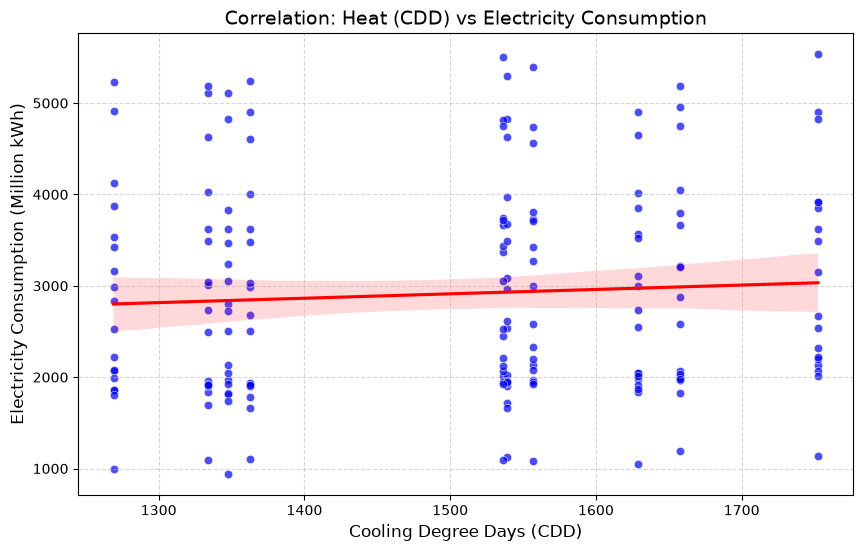

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. โหลดข้อมูลด้วย Pandas
df = pd.read_parquet("data/gold/fact_district_energy_heat_yearly.parquet")

# 2. พล็อต Scatter Plot เพื่อดูความสัมพันธ์ระหว่าง CDD (ความร้อน) กับค่าไฟ
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="cdd", y="consumption_million_kwh", alpha=0.7, color="blue")

# เพิ่มเส้นแนวโน้ม (Trendline)
sns.regplot(data=df, x="cdd", y="consumption_million_kwh", scatter=False, color="red")

plt.title("Correlation: Heat (CDD) vs Electricity Consumption", fontsize=14)
plt.xlabel("Cooling Degree Days (CDD)", fontsize=12)
plt.ylabel("Electricity Consumption (Million kWh)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()